# SHAP explainability analysis

This notebook explains how the fitted prediction models use the available admission-level variables to generate ESBL-risk predictions. It is an interpretation analysis, not a model-training or performance-evaluation analysis.

## Main questions

- Which variables contribute most strongly to each model's predictions?
- Which variables tend to increase or decrease predicted risk?
- Do different model types rely on different variables?

SHAP values describe the contribution of a feature to an individual model prediction relative to the model's baseline prediction. They describe model behaviour and should not be interpreted as causal effects. A feature with a large SHAP value is influential for the model; this does not prove that changing the feature would change a patient's underlying ESBL risk.

## Data and interpretation set

The analysis uses the temporal test set. This is intentional: explanations should reflect the model's behaviour on admissions that were not used for model fitting. Rows with unresolved or unknown outcomes are excluded from the outcome summary, although SHAP calculations themselves only require predictor values.

For computational control, the notebook may use a reproducible sample of the test set. The sample size is controlled by `explainability.shap_max_rows`. Sampling affects the precision of the global importance summary, but it does not change the fitted model or its predictions. Set the value to the full test-set size when the dataset is small enough.

In [11]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [12]:
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import pandas as pd
import yaml
from IPython.display import display

from icare_risk.data.audit import load_admission_file
from icare_risk.models.training import encode_binary_target
from icare_risk.explainability import (
    calculate_shap_values,
    shap_importance_table,
    shap_values_table,
)

CONFIG_PATH = Path('../src/icare_risk/config/icare/analysis.yaml')
with CONFIG_PATH.open() as f:
    config = yaml.safe_load(f)

df = load_admission_file(config['outputs']['processed_dataset'])
target = config['columns']['target']
test = df.loc[df['split'].eq('test')].copy()
mapping = config.get('target_mapping', {})
test['__binary_target__'] = encode_binary_target(
    test[target],
    positive_values=mapping.get('positive_values'),
    negative_values=mapping.get('negative_values'),
)
test = test.dropna(subset=['__binary_target__'])
y_test = test['__binary_target__'].astype(int)

max_rows = config.get('explainability', {}).get('shap_max_rows', 2000)
if len(test) > max_rows:
    test = test.sample(max_rows, random_state=42)
    y_test = test['__binary_target__'].astype(int)
print(f'SHAP rows: {len(test):,}; events: {y_test.sum():,}')

SHAP rows: 2,000; events: 406


## Load the fitted models

Each saved model bundle contains both the fitted pipeline and the raw feature list used during training. Using that stored feature list is essential: the SHAP input must contain exactly the variables expected by the fitted model, in the correct preprocessing pathway.

The models are not refitted here. This notebook only loads models created by `03_train_models.ipynb` and explains their predictions. If the feature configuration or model parameters change, rerun model training before rerunning this notebook.

In [17]:
model_directory = Path(config['outputs']['model_directory'])
fitted_models = {}
feature_map = {}
for model_cfg in config['models']:
    name = model_cfg['name']
    bundle = joblib.load(model_directory / f'{name}.joblib')
    fitted_models[name] = bundle['model']
    feature_map[name] = bundle['features']
print('Available models:')
for m in fitted_models:
    print(f"    - {m}")

Available models:
    - lr_kim_score
    - lr_all_scores
    - lr_clinical_baseline
    - xgb_kim_score
    - xgb_all_scores
    - xgb_clinical_baseline


## Calculate SHAP values and global importance

For every model, the reusable explainability function transforms the raw admission variables through the model's fitted preprocessing pipeline and calculates feature contributions. One-hot encoded categorical variables may therefore appear as transformed feature names.

The global importance table ranks features by mean absolute SHAP value. This measures the average magnitude of contribution, regardless of direction. A high value means that a feature strongly affects predictions; it does not indicate whether the feature increases or decreases risk. Directional interpretation requires dependence plots or row-level SHAP values.

If a model uses an XGBoost compatibility fallback, the results should be described as XGBoost feature contributions on the model-margin scale rather than assumed to be identical to every SHAP explainer implementation.

In [18]:
# Create directory
output_directory = Path(config['outputs']['shap_directory'])
output_directory.mkdir(parents=True, exist_ok=True)

# Variables
global_tables = []
individual_tables = []
shap_results = {}

for name, model in fitted_models.items():
    features = feature_map[name]
    X_test = test[features]
    print(f'Calculating SHAP values for {name} ({len(X_test):,} rows, {len(features)} raw features)...')
    values, transformed_names = calculate_shap_values(model, X_test)
    shap_results[name] = (values, transformed_names)
    global_table = shap_importance_table(values, transformed_names, model_name=name)
    global_tables.append(global_table)
    row_table = shap_values_table(values, transformed_names, index=X_test.index)
    row_table.insert(0, 'model', name)
    row_table.insert(1, 'admission_index', X_test.index)
    individual_tables.append(row_table)
    global_table.to_csv(output_directory / f'{name}_global_importance.csv', index=False)

global_importance = pd.concat(global_tables, ignore_index=True)
shap_values = pd.concat(individual_tables, ignore_index=True)
global_importance.to_csv(output_directory / 'shap_global_importance.csv', index=False)
shap_values.to_parquet(output_directory / 'shap_values.parquet', index=False)
display(global_importance.groupby('model', group_keys=False).head(20))

Calculating SHAP values for lr_kim_score (2,000 rows, 5 raw features)...
Calculating SHAP values for lr_all_scores (2,000 rows, 6 raw features)...
Calculating SHAP values for lr_clinical_baseline (2,000 rows, 16 raw features)...
Calculating SHAP values for xgb_kim_score (2,000 rows, 5 raw features)...
Calculating SHAP values for xgb_all_scores (2,000 rows, 6 raw features)...
Calculating SHAP values for xgb_clinical_baseline (2,000 rows, 16 raw features)...


,model,feature,mean_abs_shap,mean_shap,importance_rank
0,lr_kim_score,numeric__kim_hx_prior_antibiotics_90d,0.013505,-0.003474,1
1,lr_kim_score,numeric__kim_hx_prior_esbl,0.001338,0.000806,2
2,lr_kim_score,numeric__kim_hx_recent_hosp_1yr,0.000000,0.000000,3
3,lr_kim_score,numeric__kim_hx_nursing_home_resident,0.000000,0.000000,4
4,lr_kim_score,numeric__kim_hx_urinary_catheter,0.000000,0.000000,5
...,...,...,...,...,...
70,xgb_clinical_baseline,categorical__GENDER_DESC_Female,0.012175,0.000213,16
71,xgb_clinical_baseline,numeric__charlson_hx_renal_mod_sev,0.012038,0.005691,17
72,xgb_clinical_baseline,categorical__INDEX_OF_MULTIPLE_DEPRIVATION_DEC...,0.011921,-0.000293,18
73,xgb_clinical_baseline,categorical__GENDER_DESC_Male,0.011590,-0.000593,19


## Visualise the most influential features

These bar charts show the top features by mean absolute SHAP value for each model. They are global summaries: they answer which variables matter most on average across the sampled test admissions. They do not show the direction of an individual feature's effect.

For publication, retain the exact CSV tables alongside the figures. The plots are intended to communicate the main ranking clearly, while the tables preserve the full precision and all transformed feature names.

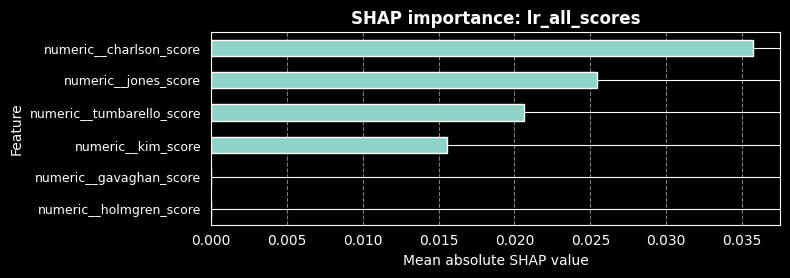

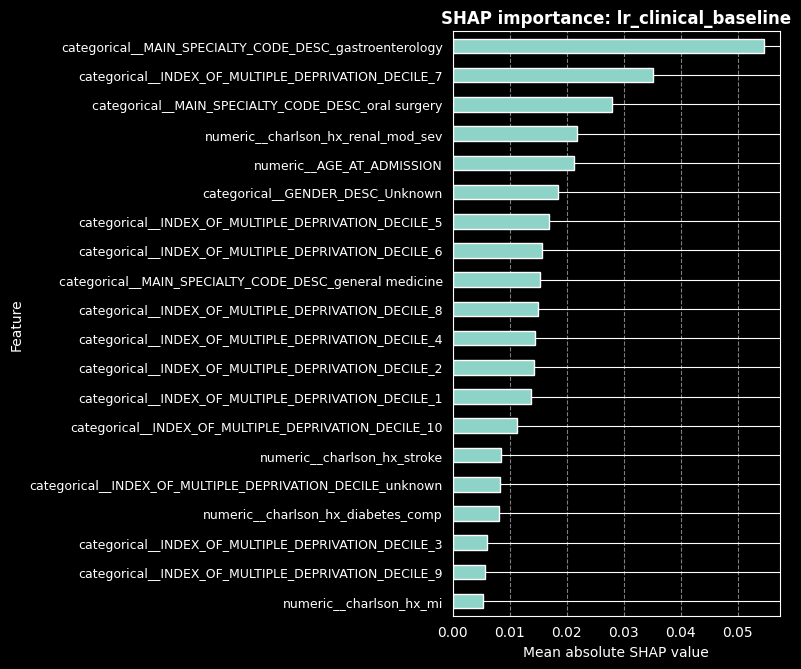

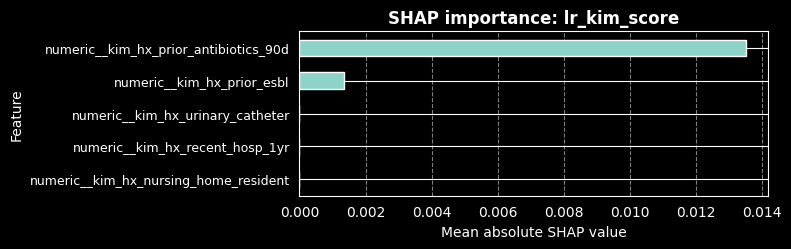

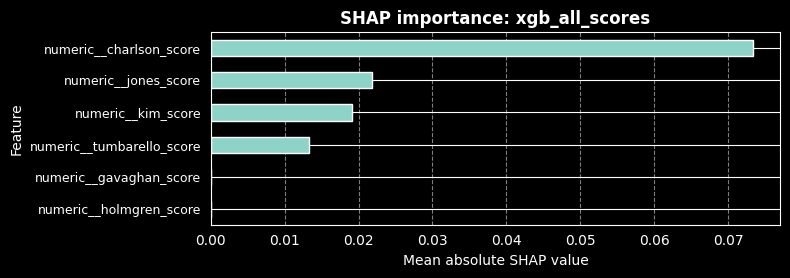

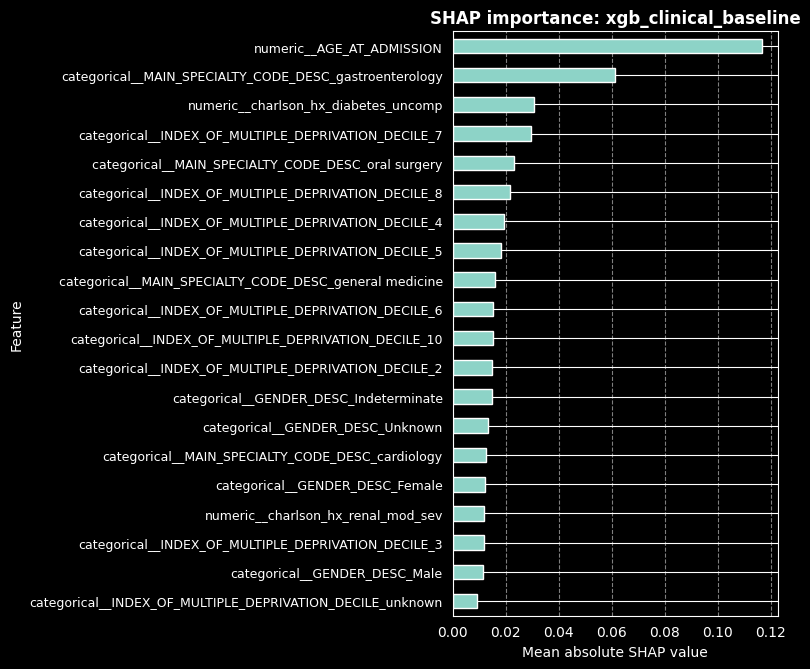

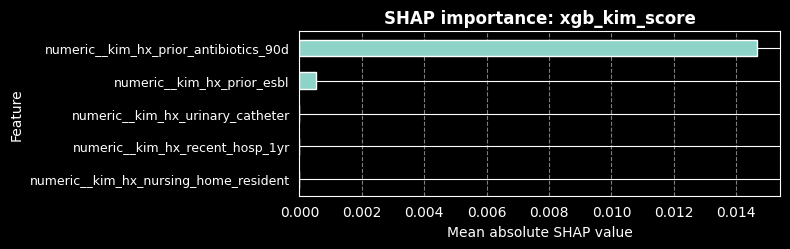

Saved consistent row-height figures in 'results/feature_importance/shap'


In [25]:
# Fixed row-height SHAP importance plots
# Each row takes the exact same vertical space across all figures.
row_height = 0.28  # Adjust this value to make rows closer (e.g., 0.22) or wider (e.g., 0.35)
base_height = 1.2  # Extra space for titles, axis labels, and margins

for name, group in global_importance.groupby('model'):
    top = group.nlargest(20, 'mean_abs_shap').sort_values('mean_abs_shap')

    # Dynamically scale figure height directly proportional to the number of features
    n_features = len(top)
    fig_height = base_height + (n_features * row_height)

    fig, ax = plt.subplots(figsize=(8, fig_height))
    top.plot.barh(x='feature', y='mean_abs_shap', legend=False, ax=ax)

    ax.set_title(f'SHAP importance: {name}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Mean absolute SHAP value', fontsize=10)
    ax.set_ylabel('Feature', fontsize=10)

    ax.tick_params(axis='y', labelsize=9)
    ax.grid(axis='x', linestyle='--', alpha=0.5)
    plt.tight_layout()

    output_path = output_directory / f'{name}_shap_importance.png'
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()

print(f"Saved consistent row-height figures in '{output_directory}'")

## Interpretation checklist

Before interpreting the results, confirm that:

1. The models were trained using only variables available at the intended prediction time.
2. Outcome-derived variables and post-admission variables were excluded.
3. The displayed model feature list matches the saved training bundle.
4. Global importance is not being interpreted as causality.
5. Correlated variables are interpreted cautiously: SHAP importance may be distributed across correlated predictors.
6. Results are considered alongside temporal performance, calibration, subgroup performance, and clinical plausibility.

The final outputs are saved under the configured SHAP directory.